sorted procesed conductivities
{-2.0: {'mean': np.float64(12845475.815421),
        'std': np.float64(529723.5105419041)},
 -1.0: {'mean': np.float64(14439835.866362244),
        'std': np.float64(904927.1399689652)},
 -0.0: {'mean': np.float64(7737502.982245647),
        'std': np.float64(328614.2269671022)},
 2.0: {'mean': np.float64(6448612.76258447),
       'std': np.float64(271078.514750238)},
 5.0: {'mean': np.float64(5958020.85618009),
       'std': np.float64(507929.89586580213)},
 7.5: {'mean': np.float64(5473082.318815806),
       'std': np.float64(202927.96128556354)},
 10.0: {'mean': np.float64(5242825.073787406),
        'std': np.float64(324224.2660898014)},
 12.5: {'mean': np.float64(5000475.709584896),
        'std': np.float64(110260.8327607896)},
 15.0: {'mean': np.float64(4223838.308813534),
        'std': np.float64(152215.81466074625)},
 25.0: {'mean': np.float64(4122942.9761048234),
        'std': np.float64(106564.43380468825)},
 50.0: {'mean': np.float64(3708819

<>:82: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:102: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:82: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:102: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/rf/s1m2r2bn7nx64szrkz747pb40000gn/T/ipykernel_66174/1707653911.py:82: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.ylabel(r"$\sigma_{THz}(\omega)\:(S/m)$")
/var/folders/rf/s1m2r2bn7nx64szrkz747pb40000gn/T/ipykernel_66174/1707653911.py:102: SyntaxWarning: "\s" i

FileNotFoundError: /Users/yuewang/SLAC/goldthz/processed_data/single_shot/lasernet_plots/Zhijiang_data_Fig4.txt not found.

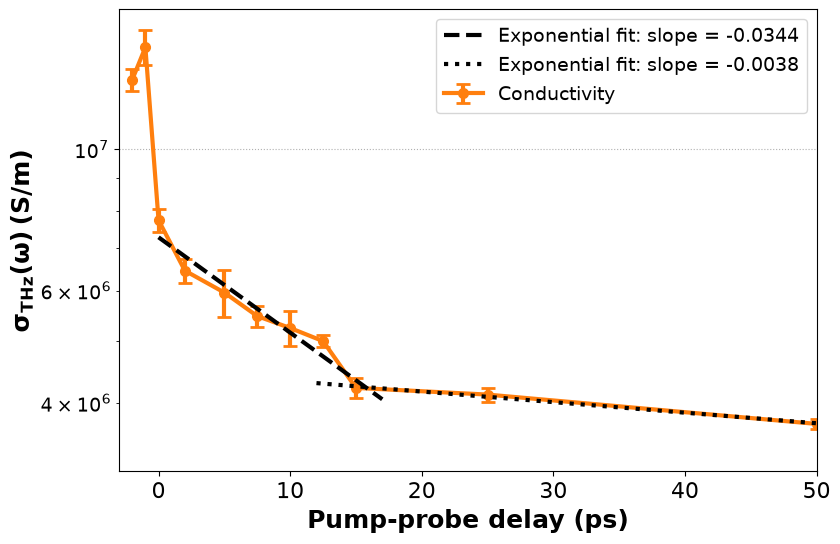

In [ ]:
# fourier transform of THz waveform

import matplotlib.pyplot as plt
import numpy.fft as fft
import numpy as np
import os
from scipy.optimize import curve_fit
from pprint import pprint
import json
from myfuncs.utility import saveDict

def renameKeys(old_data): # rename keys to float, then sort by key
    new_data = {}
    for key, value in old_data.items():
        if key.startswith('neg'):
            key = key.replace('neg', '-')
            new_key = float(key)
        elif key.startswith('pos'):
            key = key.replace('pos', '')
            if 'p' in key:
                key = key.replace('p', '.')
            new_key = float(key)
        else:
            new_key = key
        new_data[new_key] = value
    sort_data = dict(sorted(new_data.items()))
    return sort_data

file_root = '/Users/yuewang/SLAC/goldthz/Au_data/400nm/processed_data/single_shot/'

wp = 'wp41'
pos = 'pos10'

# sigma vars
Z0 = 376.73
nSi3N4 = 2.7

sigmaData = {} # for storing mean sigmas at each pos

positions = ['neg0', 'neg1', 'neg2', 'pos2', 'pos5', 'pos7p5', 'pos10', 'pos12p5', 'pos15', 'pos25', 'pos50', 'pos100']
for pos in positions:
    realSigmas = [] # for calculating means across shots for each pos

    for shot in range(8):
        if not os.path.exists(file_root + f'SS_Au_{wp}_{pos}_shot_{shot:04d}/'):
            continue

        file_path = file_root + f'SS_Au_{wp}_{pos}_shot_{shot:04d}/'
        # load data
        post_bal_raw = np.loadtxt(file_path + 'THz_post_bal.dat')
        post_bal = np.mean(post_bal_raw, axis=1)  # average over the columns
        shot_bal = np.loadtxt(file_path + 'THz_shot_bal.dat')
        time_axis = np.loadtxt(file_path + 'time_axis.dat')

        # compute frequency axis 
        dt = time_axis[1] - time_axis[0]
        N = len(time_axis)

        # zero padding
        Nfft = 5336 # 8 times number of data points

        # padded fft
        ref_fft = fft.fft(post_bal, n=Nfft)
        sig_fft = fft.fft(shot_bal, n=Nfft)
        trans_fft = sig_fft / ref_fft

        freq = fft.fftfreq(Nfft, dt)
        # sort by frequency
        index = np.argsort(freq)
        frq_sort = freq[index]
        ref_sort = ref_fft[index]
        sig_sort = sig_fft[index]
        """
        plt.figure()
        plt.plot(frq_sort, np.abs(ref_sort), "-b", label="post-shot")
        plt.plot(frq_sort, np.abs(sig_sort), "-r", label="on-shot")
        plt.title(f"post vs on-shot for Au: {wp} {pos} {shot:04d}")
        plt.xlabel("Frequency (THz)")
        plt.ylabel(r"$\sigma_{THz}(\omega)\:(S/m)$")
        plt.xlim(0, 6)
        """

        # finding the mean sigma in a freq range per shot
        sThickness = 30e-9
        transfer = sig_sort/ref_sort
        sigma = ((1 + nSi3N4) / (Z0*sThickness)) * ((1/transfer) - 1)
        sigmaReal = np.real(sigma)
        if shot == 3:
            sigmaMean = np.mean(sigma[(frq_sort >= 0.7) & (frq_sort <= 0.9)])
        else:
            sigmaMean = np.mean(sigma[(frq_sort >= 0.7) & (frq_sort <= 0.9)])
        realSigmas.append(np.real(sigmaMean))

        """
        plt.figure()
        plt.plot(frq_sort, sigmaReal, "-b", label="conductivity")
        plt.title(f"Conductivity vs Frequency for Au: {wp} {pos} {shot:04d}")
        plt.xlabel("Frequency (THz)")
        plt.ylabel(r"$\sigma_{THz}(\omega)\:(S/m)$")
        plt.xlim(0, 6)

        if not os.path.exists(file_root + '/conductivity plots/' + f'SS_Au_{wp}_{pos}'):
            os.makedirs(file_root + '/conductivity plots/' + f'SS_Au_{wp}_{pos}')

        if not os.path.exists(file_root + '/conductivity plots/' + f'SS_Au_{wp}_{pos}/sigma_shot_{shot:04d}.png'):
            plt.savefig(file_root + '/conductivity plots/' + f'SS_Au_{wp}_{pos}/sigma_shot_{shot:04d}.png', dpi=300)
        """
        
    realSigmaMean = np.mean(realSigmas) # realSigmas holds the mean sigma for each shot at a delay
    realSigmaStd = np.std(realSigmas)
    sigmaData[pos] = {"mean": realSigmaMean, "std": realSigmaStd}
sortedSigmaData = renameKeys(sigmaData)

SAVE = True

if SAVE:
    saveDict(sortedSigmaData, '/Users/yuewang/SLAC/goldthz/Au_data/code/' + 'FFT method/' + '400_nm_FFT.json')

print("sorted procesed conductivities")
pprint(sortedSigmaData)
# conductivity vs delay figure 
plt.figure(figsize=(9,6))
yErr = [v["std"] for v in sortedSigmaData.values()]
plt.errorbar(list(sortedSigmaData.keys()), [v["mean"] for v in sortedSigmaData.values()], fmt="-ob", color="tab:orange", yerr=yErr, capsize=5, capthick=2, ms=7, label="Conductivity", lw=3)
# plt.title(f"Conductivity vs Delay for Au: {wp}")
plt.xlabel("Pump-probe delay (ps)", fontsize=18, weight='bold')
plt.ylabel(r"$\mathbf{\sigma_{THz}(\omega)\:(S/m)}$", fontsize=18)
plt.xlim(-3, 50)
plt.yticks(fontsize=16)
plt.tick_params(which="both", axis="both", labelsize=14)

plt.xticks(fontsize=16)
plt.yscale('log')

# determine exponential decay regression for conductivity vs delay between 0 and 15 ps
delay_range = [t for t in sortedSigmaData.keys() if 0 <= t <= 15]
mean_values = [sortedSigmaData[t]["mean"] for t in delay_range]
# fit the logarithm of the data to a linear function
log_mean_values = np.log(mean_values)
slope, intercept = np.polyfit(delay_range, log_mean_values, 1)
yExp1 = [np.exp(slope * t + intercept) for t in delay_range]
label = f"Exponential fit: slope = {slope:.4f}"
plt.plot(delay_range, yExp1, "--k", label=f"Exponential fit: slope = {slope:.4f}", lw=3, zorder=3)

# determine exponential decay regression between 15 and 100 ps
meltX = [t for t in sortedSigmaData.keys() if 15 <= t <= 50]
meltMean = [sortedSigmaData[t]["mean"] for t in meltX]
# fit the logarithm of the data to a linear function
logMelt = np.log(meltMean)
slopeM, interceptM = np.polyfit(meltX, logMelt, 1)
extendX = [12, *meltX]
yExp2 = [np.exp(slopeM * t + interceptM) for t in extendX]
plt.plot(extendX, yExp2, ":k", label=f"Exponential fit: slope = {slopeM:.4f}", lw=3, zorder=3)
plt.legend(fontsize=14)
plt.grid(axis='y', ls=':')

# FLASH data
file_root = '/Users/yuewang/SLAC/goldthz/processed_data/single_shot/lasernet_plots/'

delay, sigma, upErr, lowErr = np.loadtxt(file_root + "Zhijiang_data_Fig4.txt", unpack=True)
sigma = sigma * 1e7
upErr = upErr * 1e7
lowErr = lowErr * 1e7
plt.errorbar(delay, sigma, yerr=(upErr,lowErr), fmt="-o", color="tab:cyan", alpha=0.5, capsize=5)

# regression 0-14.5 ps
x1 = [delay[i] for i in range(len(delay)) if 0 <= delay[i] <= 14.5]
y1 = [sigma[i] for i in range(len(delay)) if 0 <= delay[i] <= 14.5]
logY1 = np.log(y1)
slopeZ, interceptZ = np.polyfit(x1, logY1, 1)
print(f"Z. Chen slope (0-14.5 ps): {slopeZ}")
yExp2 = [np.exp(slopeZ * t + interceptZ) for t in x1]
plt.plot(x1, yExp2, "--", color="tab:red", label=f"Z. Chen, 2021 exponential fit: slope = {slopeZ:.4f}", lw=3, zorder=4)
plt.legend(fontsize=14)
plt.grid(axis='y', ls=':')

x1 = [delay[i] for i in range(len(delay)) if 14.5 <= delay[i]]
y1 = [sigma[i] for i in range(len(delay)) if 14.5 <= delay[i]]
logY1 = np.log(y1)
slopeZ, interceptZ = np.polyfit(x1, logY1, 1)
print(f"Z. Chen slope (0-14.5 ps): {slopeZ}")
yExp2 = [np.exp(slopeZ * t + interceptZ) for t in x1]
plt.plot(x1, yExp2, ":", color="tab:red", label=f"Z. Chen, 2021 exponential fit: slope = {slopeZ:.4f}", lw=3, zorder=5)
plt.legend(fontsize=14)
plt.grid(axis='y', ls=':')

if not os.path.exists(file_root + '/lasernet_plots'):
    os.makedirs(file_root + "/lasernet_plots")

# plt.savefig(file_root + 'lasernet_plots/' + f'{wp}_conductivity.png', dpi=300, bbox_inches='tight', edgecolor='white', facecolor='none')
plt.savefig(file_root + 'lasernet_plots/' + f'{wp}_Zhijian_conductivity.png', dpi=300, bbox_inches='tight', edgecolor='white', facecolor='none')



In [ ]:
'Real Sigma Mean: 9067706.373039754'
'Real Sigma Mean: 6022044.625115885'


'Real Sigma Mean: 6022044.625115885'

{-2.0: {'mean': np.float64(nan), 'std': np.float64(nan)},
 -1.0: {'mean': np.float64(nan), 'std': np.float64(nan)},
 -0.0: {'mean': np.float64(nan), 'std': np.float64(nan)},
 2.0: {'mean': np.float64(nan), 'std': np.float64(nan)},
 5.0: {'mean': np.float64(nan), 'std': np.float64(nan)},
 7.5: {'mean': np.float64(nan), 'std': np.float64(nan)},
 10.0: {'mean': np.float64(nan), 'std': np.float64(nan)},
 12.5: {'mean': np.float64(nan), 'std': np.float64(nan)},
 15.0: {'mean': np.float64(nan), 'std': np.float64(nan)},
 25.0: {'mean': np.float64(nan), 'std': np.float64(nan)},
 50.0: {'mean': np.float64(nan), 'std': np.float64(nan)},
 100.0: {'mean': np.float64(nan), 'std': np.float64(nan)}}


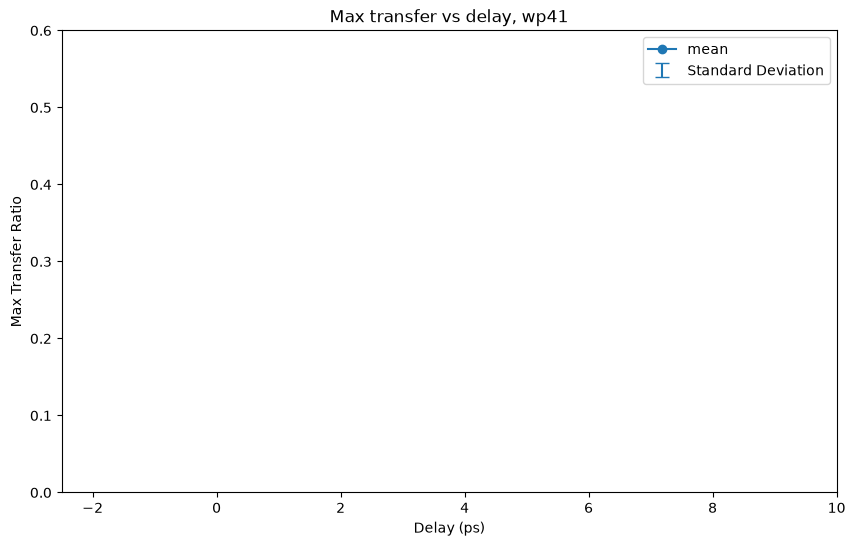

In [ ]:
# returns mean and std deviation for the max transfer of all pos for wp41

def maxRatioMean():
    data = {}
    positions = ['neg0', 'neg1', 'neg2', 'pos2', 'pos5', 'pos7p5', 'pos10', 'pos12p5', 'pos15', 'pos25', 'pos50', 'pos100']
    wp = 'wp41'
    for pos in positions:
    # loop over all shots for one wp and pos

        maxRatios = np.array([]) # store avg max ratios
        for shot in range(8):

            if not os.path.exists(file_root + f'SS_Au_{wp}_{pos}_shot_{shot:04d}/'):
                continue

            file_path = file_root + f'SS_Au_{wp}_{pos}_shot_{shot:04d}/'

            # load data
            post_bal_raw = np.loadtxt(file_path + 'THz_post_bal.dat')
            post_bal = np.mean(post_bal_raw, axis=1)  # average over the columns
            shot_bal = np.loadtxt(file_path + 'THz_shot_bal.dat')
            ref_fft = fft.fft(post_bal, n=Nfft)
            sig_fft = fft.fft(shot_bal, n=Nfft)
            ref_sort = ref_fft[index]
            sig_sort = sig_fft[index]

            maxRef = np.max(np.abs(ref_sort))
            maxSig = np.max(np.abs(sig_sort))
            maxRatio = maxSig / maxRef
            maxRatios = np.append(maxRatios, maxRatio)

        avgMaxRatio = np.mean(maxRatios)
        stdMaxRatio = np.std(maxRatios)
        data[pos] = {"mean": avgMaxRatio, "std": stdMaxRatio}

    return data

data = maxRatioMean()

data = renameKeys(data)
pprint(data)

# plot means and std
plt.figure(figsize=(10,6))
xAx = [pos for pos in data.keys()]
yAx = [mean for mean in [data[pos]["mean"] for pos in data.keys()]]
plt.plot(xAx, yAx, "-o", label="mean")
yAxErr = [std for std in [data[pos]["std"] for pos in data.keys()]]
plt.errorbar(xAx, yAx, yerr=yAxErr, fmt="none", capsize=5, capthick=1, label="Standard Deviation")
plt.xlim(-2.5, 10)
plt.ylim(0, 0.6)

plt.legend()
plt.xlabel("Delay (ps)")
plt.ylabel("Max Transfer Ratio")
plt.title(f"Max transfer vs delay, {wp}")

plt.show()

